# Solar filament segmentation: the full pipeline

Solar Filament Segmentation Challenge 2026 (IEEE BigData Cup, Kaggle). Team: J. Samadov, N. S. Dzhalilov, A. Habilov.

This notebook goes through the submitted pipeline and rebuilds the submitted file from the models' saved outputs:

1. **Data.** 707 GONG H$\alpha$ photographs (2048 × 2048), each outlined by one to three experts.
2. **Models.**
   - Ten full-frame U-Nets: ResNet-34 and ResNet-50 encoders × 5 folds.
   - A segmenter built on the vision encoder of Qwen3-VL-2B, pre-trained on unlabelled GONG frames.
   - YOLO11l-seg per fold.
   - All trained on Kaggle GPUs by the kernels in `kernels/` (`kernels/build.py` writes them from `kernels/aug_unet/`).
3. **Inference.** The ten U-Net maps (each averaged over the 8 symmetries of the square) and the Qwen map are averaged, with weight 2/12 for Qwen.
4. **Candidates.** Connected regions of the mean map above 0.6, pieces closer than 3 px joined, area ≥ 100 px. Each candidate has 21 features: appearance, its place in a threshold/join grid, heliographic latitude, longitude from the central meridian, axis orientation.
5. **Selection rule.** Gradient-boosted trees predict each candidate's IoU with the experts from those features plus four YOLO11 agreement features. They are trained on the out-of-fold candidates of all 707 photographs, and the cut is chosen on fold 0's ensemble. Kept candidates are written as COCO RLE.

| | fold-0 validation PQ (nested) | public test PQ |
|---|---|---|
| single ResNet-50 U-Net, D4 | 0.434 | 0.36 |
| + ensemble and selection rule | 0.440 | 0.38 |
| ten fold models, rule with heliographic features | 0.452 | 0.38 |
| + Qwen segmenter map + YOLO11 features (**submitted**) | **0.458** | **0.39** |

The technical report (`report/`) describes the method, the evaluation and what else we tried.

**Running it.** Nothing here needs a GPU: the networks' probability maps were written by the training kernels.
- **On Kaggle:** attach the competition data and the outputs of the ten kernels listed below.
- **Locally:**
  - Put the competition data in `MAGFiLO_1.0_Kaggle_2026/`: `kaggle competitions download -c filament-segmentation-2026`, then unzip.
  - The next cell downloads the kernels' outputs with the Kaggle CLI.
- Step 5 refits the rule on all 707 photographs, which takes about an hour on 4 CPU cores.

In [1]:
import hashlib, inspect, json, os, subprocess, sys, time
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kernels" / "aug_unet" / "kfold.py").exists())
CODE = REPO / "kernels" / "aug_unet"
sys.path.insert(0, str(CODE))

import run                   # data split, U-Net, training loop, PQ (imports torch before cv2)
import post_local as P       # reading the saved probability maps
import candidate_pool as C   # candidate filaments and their features
import kfold as K            # out-of-fold evaluation, ensembles, the selection rule, the test CSV
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn, torch

VARIANT = "q"   # which Qwen maps the final map carries (kfold.Q2_MIXES); "q" is the submitted file
SUBMITTED_MD5 = "003770e26a0f962a45c8227320e1e145"   # submission_kf10q_rule_geo_yolo.csv, public PQ 0.39
EXTRAS = dict(K.Q2_MIXES)[VARIANT]
print(f"python {sys.version.split()[0]}, torch {torch.__version__}, numpy {np.__version__}, "
      f"opencv {cv2.__version__}, scikit-learn {sklearn.__version__}, on Kaggle: {ON_KAGGLE}")
print("Qwen maps in the final map:", EXTRAS)

python 3.13.18, torch 2.11.0+cpu, numpy 2.1.3, opencv 4.14.0, scikit-learn 1.6.1, on Kaggle: True
Qwen maps in the final map: ('qwenseg_pre/plain',)


In [2]:
# the training kernels' outputs: probability maps (val/test, plain and D4) and YOLO predictions
KERNELS = ["filament-aug-dump", "filament-unet-r2", "filament-unet-r3", "filament-unet-r5", "filament-unet-r6",
           "filament-unet-r7", "filament-unet-r8", "filament-yolo", "filament-yolo-b", "filament-qwen-seg"]
if any(e.split("/")[0].endswith("2") for e in EXTRAS):
    KERNELS.append("filament-qwen-seg2")
if ON_KAGGLE:
    SRC, D, OUT = Path("/kaggle/input"), Path("/tmp/fil_post"), Path("/kaggle/working")
else:
    SRC, D, OUT = REPO / "inputs", REPO / "inputs" / "work", REPO / "notebooks" / "out"
    for k in KERNELS:
        if not (SRC / k).exists():
            subprocess.run(["kaggle", "kernels", "output", f"jannatsamadov/{k}", "-p", str(SRC / k)], check=True)
OUT.mkdir(parents=True, exist_ok=True)
models = P.extract(SRC, D)
print(len(models), "saved models' maps:", ", ".join(models))

16 saved models' maps: flip, full, qwenseg_ft, qwenseg_pre, r34f1, r34f2, r34f3, r34f4, r50, r50all, r50f1, r50f2, r50f3, r50f4, solar, union


## 1. Data, and how much the experts disagree

Each training photograph was outlined by one to three experts. The scorer treats every expert's set as a separate ground truth and pools them. Two experts agree with each other at PQ 0.35 only, and they disagree mostly on *whether* a faint filament is there, not on *where* its edge runs. The training target of a pixel is therefore the fraction of experts who drew it.

707 training photographs, 8199 outlines; photographs by number of experts: {1: 411, 2: 145, 3: 151}


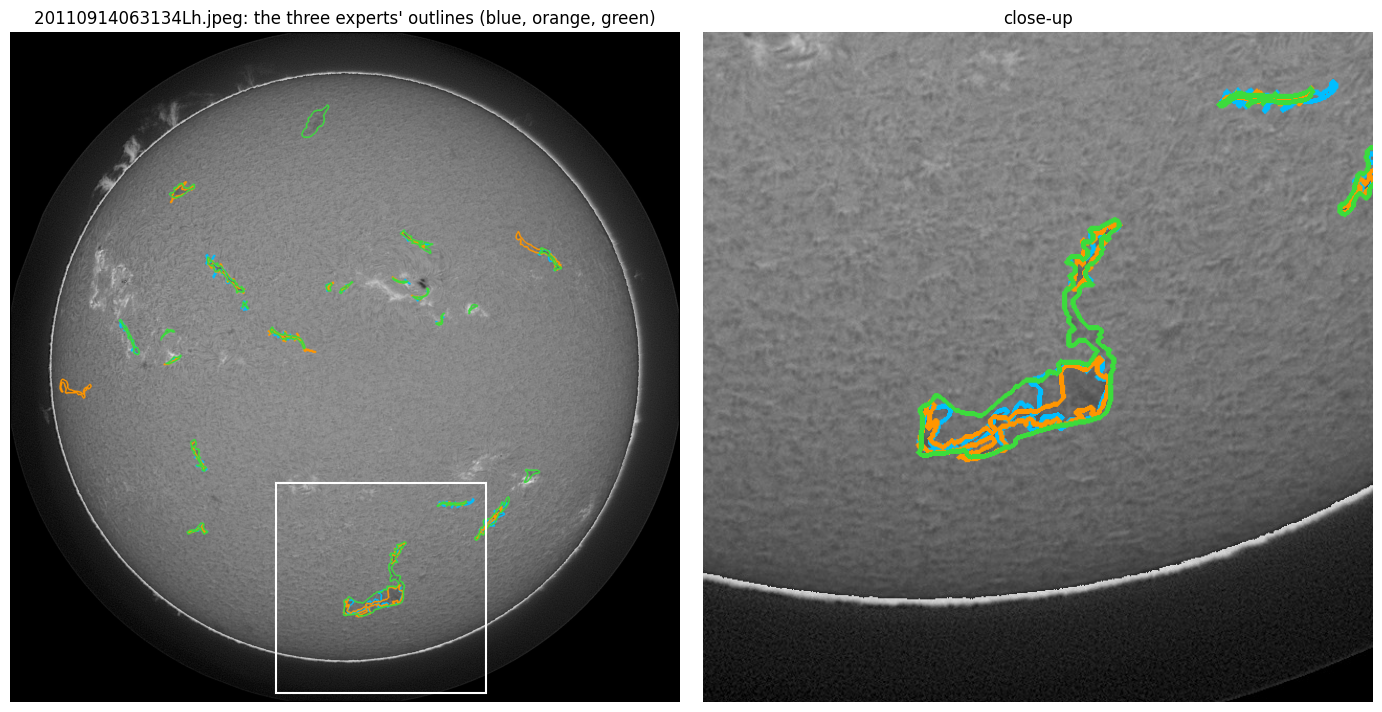

In [3]:
ann_path, tr_dir, te_dir = run.find_data()
coco = json.load(open(ann_path))
sets_of, by_set = {}, {}
for im in coco["images"]:                       # one entry per photograph and expert
    sets_of.setdefault(im["file_name"], []).append(im["id"])
for a in coco["annotations"]:
    by_set.setdefault(a["image_id"], []).append(a)
n_exp = np.bincount([len(v) for v in sets_of.values()])
print(f"{len(sets_of)} training photographs, {len(coco['annotations'])} outlines;",
      "photographs by number of experts:", {k: int(n) for k, n in enumerate(n_exp) if n})

three = sorted(f for f, s in sets_of.items() if len(s) == 3)
EXAMPLE = max(three, key=lambda f: sum(len(by_set.get(s, [])) for s in sets_of[f]))
img = cv2.imread(str(tr_dir / EXAMPLE), cv2.IMREAD_GRAYSCALE)
over = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
union = np.zeros(img.shape, np.uint8)
for col, sid in zip([(0, 190, 255), (255, 150, 0), (60, 220, 60)], sets_of[EXAMPLE]):
    for a in by_set.get(sid, []):
        m = run.ann_mask(a).astype(np.uint8)
        union |= m
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(over, cs, -1, col, 3)
n, lab, st, cen = cv2.connectedComponentsWithStats(cv2.dilate(union, np.ones((41, 41), np.uint8)))
cx, cy = cen[1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))].astype(int)
y0, x0 = int(np.clip(cy - 320, 0, 2048 - 640)), int(np.clip(cx - 320, 0, 2048 - 640))
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(over); ax[0].add_patch(plt.Rectangle((x0, y0), 640, 640, fill=False, ec="w", lw=1.5))
ax[0].set_title(f"{EXAMPLE}: the three experts' outlines (blue, orange, green)")
ax[1].imshow(over[y0:y0 + 640, x0:x0 + 640]); ax[1].set_title("close-up")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

## 2. The models

**U-Net.**
- Architecture: torchvision ResNet-34 or ResNet-50 encoder, one grey input channel, five decoder stages (256 → 16 channels).
- Input: the whole 2048 × 2048 frame, never tiles.
- Loss: BCE (positive weight 10) plus soft Dice, both on the solar disk only.
- Optimiser: AdamW, lr 3e-4, one warm-up epoch, then cosine decay. 60 epochs for ResNet-34, 45 for ResNet-50.
- Augmentation: rotation by any angle about the disk centre, mirrors, and photometric changes within the ranges measured between GONG frames.
- Training kernels: `filament-aug-dump`/`-unet-r2`/`-r3` hold the fold-0 models, `-unet-r5`…`-r8` the other folds. Each kernel trains two arms, one per T4.

**Qwen3-VL segmenter** (`kernels/aug_unet/qwen_seg.py`).
- Architecture: the 24-block vision encoder of Qwen3-VL-2B with a mask decoder.
- Pre-trained for one epoch on 2000 unlabelled GONG frames, with the fold-0 U-Nets' maps as targets.
- Then fine-tuned on fold 0.

**YOLO11l-seg** (`kernels/aug_unet/yolo_seg.py`).
- One model per fold.
- Its masks are weaker (PQ 0.385), so it enters only as an independent opinion on each candidate.

In [4]:
for enc in ("resnet34", "resnet50"):
    net = run.UNet(enc, pretrained=False)
    print(f"U-Net with a {enc} encoder: {sum(p.numel() for p in net.parameters()) / 1e6:.1f} M parameters")
del net
print("\n" + inspect.getsource(run.loss_fn))
print("training runs: each is a Kaggle kernel, each arm one T4 (defaults:", run.ARM_DEFAULTS, ")")
for r in ("r1", "r2", "r3", "r5", "r6", "r7", "r8"):
    print(f"  {r}: {run.RUNS[r]}")
print("\nfold-0 ensemble:", K.ENS0, "\nfold models:", K.FAMILIES)

U-Net with a resnet34 encoder: 24.4 M parameters
U-Net with a resnet50 encoder: 32.5 M parameters

def loss_fn(logit, y, valid, pos_weight=10.0):
    """BCE + soft Dice, on-disk pixels only. Targets are soft (annotator fraction)."""
    pw = torch.tensor(pos_weight, device=logit.device)
    bce = F.binary_cross_entropy_with_logits(logit, y, pos_weight=pw, reduction="none")
    bce = (bce * valid).sum() / (valid.sum() * logit.shape[0])
    p, t = torch.sigmoid(logit) * valid, y * valid
    dice = 1.0 - (2.0 * (p * t).sum((1, 2, 3)) + 1.0) / (p.sum((1, 2, 3)) + t.sum((1, 2, 3)) + 1.0)
    return bce + dice.mean(), bce.detach(), dice.mean().detach()

training runs: each is a Kaggle kernel, each arm one T4 (defaults: {'aug': 'full', 'encoder': 'resnet34', 'target': 'soft', 'init': 'imagenet', 'all_data': False} )
  r1: {'flip': {'aug': 'flip'}, 'full': {'aug': 'full'}}
  r2: {'union': {'target': 'union'}, 'r50': {'encoder': 'resnet50', 'epochs': 45}}
  r3: {'solar': {'init': 'solar'}, 'r50

## 3. Inference: one averaged probability map per test photograph

Each model's map was written by its training kernel, plain and averaged over the eight symmetries of the square (D4). The final map is the mean of the ten fold U-Nets (D4) and the Qwen map. The Qwen map counts as 2 of 12, i.e. one member next to five U-Nets.

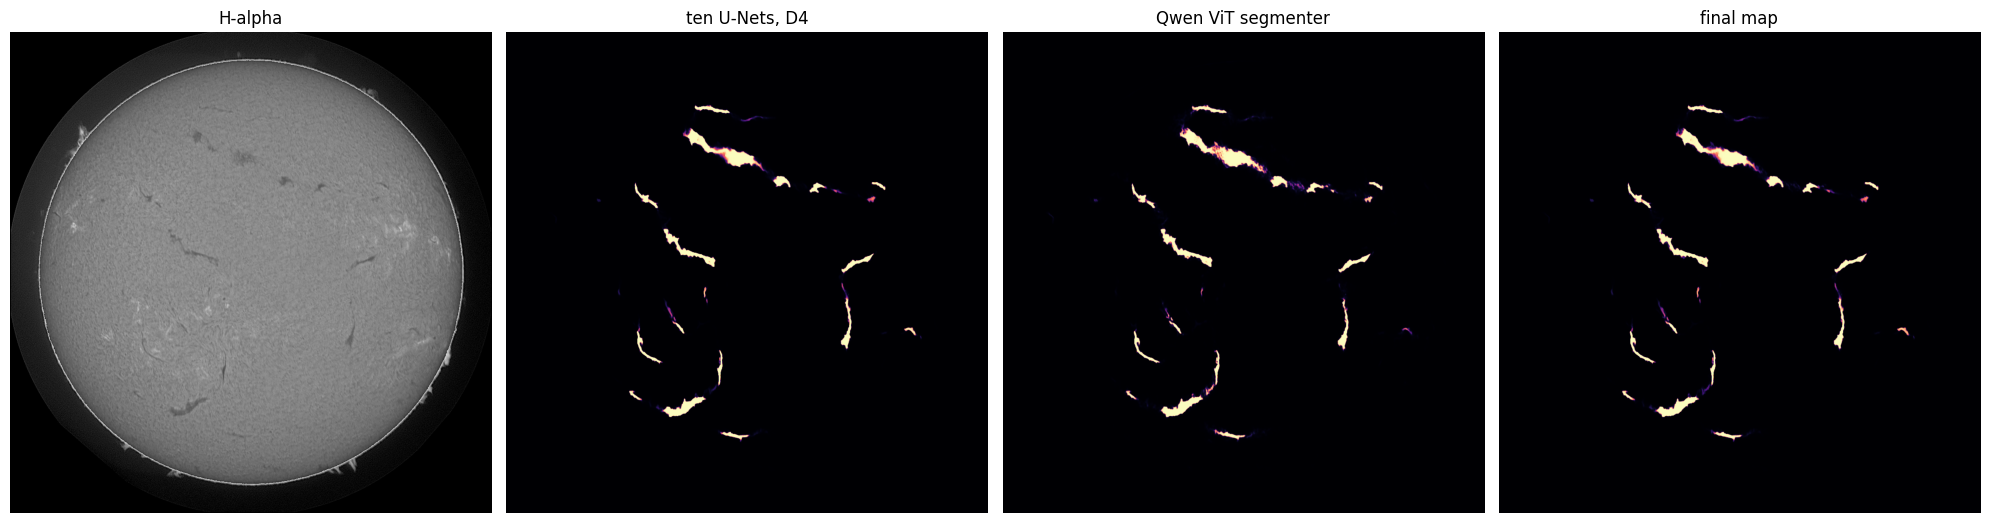

In [5]:
test_files = sorted(p.name for p in te_dir.glob("*.jpeg"))
test_stems = [Path(n).stem for n in test_files]
TEN = K.FAMILIES["r50"] + K.FAMILIES["r34"]
final_map = K.mix_dump(D, f"{VARIANT}mix10", TEN, EXTRAS, 2 * K.QSEG_W, "test", test_stems)

STEM = "20130530133654Bh"                         # the test photograph with the most filaments
img = cv2.imread(str(te_dir / f"{STEM}.jpeg"), cv2.IMREAD_GRAYSCALE)
panels = [("H-alpha", img), ("ten U-Nets, D4", P.load_map(D, "ens:" + "+".join(TEN) + "/d4", "test", STEM)),
          ("Qwen ViT segmenter", P.load_map(D, EXTRAS[0], "test", STEM)),
          ("final map", P.load_map(D, final_map, "test", STEM))]
fig, ax = plt.subplots(1, 4, figsize=(20, 5.3))
for a, (title, im) in zip(ax, panels):
    a.imshow(im[::2, ::2], cmap="gray" if title == "H-alpha" else "magma", vmin=0, vmax=255)
    a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Candidates and their features

The map is thresholded on a grid (t 0.2–0.9, join radius 0–12 px). The candidates are the regions at the one setting **t 0.6, join 3 px, area ≥ 100 px**. Each candidate carries 21 features:
- **Appearance:** area, probability statistics, elongation, darkness against a 15 px ring.
- **Place in the grid:** how its outline splits or merges at neighbouring thresholds.
- **Place on the Sun:** heliographic latitude and longitude from the central meridian (with the solar $B_0$ angle of the observation time; the frames are already north-up), and the orientation of its long axis.

In [6]:
FEATURES = ["log area", "mean p", "max p", "p90", "std p", "share p>0.8", "elongation", "distance from centre / R",
            "ring - inside brightness", "candidates in photo", "threshold", "join px", "settings giving it",
            "log parent area ratio", "children", "largest child ratio", "rim mean p", "sin latitude",
            "longitude from CM / 90deg", "cos 2 axis", "sin 2 axis"]
p = P.load_map(D, final_map, "test", STEM)
cands, X = C.candidates(p, img, run.b0_deg(STEM))
one = [n for n, c in enumerate(cands) if C.ONE_SETTING in c["from"]]
print(f"{len(cands)} distinct outlines over the grid; {len(one)} candidates at t {C.ONE_SETTING[0]}, join {C.ONE_SETTING[1]} px")
pd.DataFrame(X[one], columns=FEATURES).round(3).head(10)

176 distinct outlines over the grid; 18 candidates at t 0.6, join 3 px


,log area,mean p,max p,p90,std p,share p>0.8,elongation,distance from centre / R,ring - inside brightness,candidates in photo,...,join px,settings giving it,log parent area ratio,children,largest child ratio,rim mean p,sin latitude,longitude from CM / 90deg,cos 2 axis,sin 2 axis
0,7.569,0.961,1.000,1.000,0.082,0.930,8.363,0.784,11.349000,18.0,...,0.0,4.0,0.031,1.0,0.967,0.201,0.757,-0.165,0.957,-0.291
1,9.427,0.954,1.000,1.000,0.092,0.907,6.043,0.579,12.640000,18.0,...,0.0,4.0,0.043,1.0,0.954,0.349,0.555,-0.087,0.689,-0.724
2,7.574,0.972,1.000,1.000,0.071,0.947,1.656,0.457,23.658001,18.0,...,0.0,4.0,0.024,1.0,0.977,0.243,0.415,0.113,0.940,-0.343
3,6.480,0.961,1.000,1.000,0.082,0.922,4.619,0.743,21.459999,18.0,...,0.0,4.0,0.029,1.0,0.965,0.158,0.399,0.473,0.610,-0.792
4,7.116,0.967,1.000,1.000,0.080,0.938,1.848,0.513,23.059000,18.0,...,0.0,4.0,0.032,1.0,0.967,0.198,0.385,0.229,0.572,0.820
5,7.546,0.960,1.000,1.000,0.084,0.926,4.901,0.592,20.497999,18.0,...,0.0,4.0,0.028,1.0,0.967,0.188,0.338,-0.339,0.157,-0.988
6,5.624,0.692,0.784,0.765,0.050,0.000,2.187,0.680,15.523000,18.0,...,0.0,4.0,0.276,1.0,0.491,0.465,0.333,0.427,0.714,0.700
7,8.641,0.975,1.000,1.000,0.067,0.953,6.077,0.298,18.922001,18.0,...,0.0,4.0,0.020,1.0,0.981,0.205,0.092,-0.180,0.475,-0.880
8,7.733,0.973,1.000,1.000,0.069,0.953,6.454,0.517,22.660999,18.0,...,0.0,4.0,0.018,1.0,0.977,0.175,0.031,0.345,0.651,0.759
9,5.323,0.764,0.902,0.861,0.078,0.376,5.669,0.220,21.684000,18.0,...,0.0,4.0,0.170,1.0,0.780,0.263,-0.107,-0.129,-0.981,0.193


## 5. The selection rule

A candidate adds ½ to PQ's denominator and adds its IoU to the numerator only if it is matched. So keeping it pays only if (probability of a match) × (expected IoU) > PQ/2.

The rule is a scikit-learn `HistGradientBoostingRegressor` (300 trees, 15 leaves, learning rate 0.05). It predicts a candidate's IoU, averaged over the photograph's experts, from 25 columns: the 21 features above and four YOLO11 columns (best IoU with a YOLO mask, that mask's confidence, the best confidence at IoU ≥ 0.3, and how much of the candidate the confident YOLO masks cover).

How it is trained and scored:
- **Training data.** The out-of-fold candidates of all 707 photographs. Each photograph's map is the mean of the two U-Nets (R34 + R50) that never saw it, and its YOLO columns come from the YOLO of the same fold.
- **Out-of-fold score.** Each fold is scored by a rule trained on the other four.
- **Cut.** An averaged map is softer than a single model's, so the cut is chosen on fold 0's ensemble map, nested.

This cell computes the 707-photograph candidate pool; it is the slow step.

In [7]:
import multiprocessing as mp
t0 = time.time()
truth = K.fold_truth(False)                       # each fold's validation photographs and expert outlines
folds = np.concatenate([[n] * len(t["frames"]) for n, t in enumerate(truth)])
pool = mp.Pool(os.cpu_count() or 4)
cache = D / f"pool_oof_{K.VIEW}"
cache.mkdir(parents=True, exist_ok=True)
jobs = [(str(D), f"{K.PAIR[n]}/{K.VIEW}", stem, t["cache"], f, sets, str(cache), True)
        for n, t in enumerate(truth) for f, stem, sets in t["frames"]]
frames = K.one_setting(list(pool.imap(K.pool_job, jobs)))
frames = K.add_neighbours(frames, D, [f"{K.PAIR[g]}/{K.VIEW}" for g in folds], "val", folds, pool.imap)
yolo = K.load_yolo(SRC)
frames = K.add_yolo(frames, [yolo[g] for g in folds], "val")
print(f"{len(frames)} photographs, {sum(len(f['X']) for f in frames)} candidates, {(time.time() - t0) / 60:.0f} min")

oof = K.rule_oof(frames, folds, K.GEO_YOLO_COLS)   # each fold scored by a rule trained on the other four
print("out-of-fold on 707 photographs, the rule with its nested cut:", K.summary(oof.sum(axis=0)))
rule = K.fit(frames, np.arange(len(frames)), K.GEO_YOLO_COLS)

prepared 566 train / 141 val photographs (236 val annotation sets), 180 test, in 64s
prepared 566 train / 141 val photographs (228 val annotation sets), 180 test, in 57s
prepared 566 train / 141 val photographs (218 val annotation sets), 180 test, in 55s
prepared 566 train / 141 val photographs (242 val annotation sets), 180 test, in 62s
prepared 564 train / 143 val photographs (230 val annotation sets), 180 test, in 58s
707 photographs, 6285 candidates, 12 min
out-of-fold on 707 photographs, the rule with its nested cut: {'PQ': np.float64(0.4487), 'SQ': np.float64(0.6845), 'RQ': np.float64(0.6555), 'TP': np.float64(4738.0), 'FP': np.float64(1520.0), 'FN': np.float64(3461.0)}


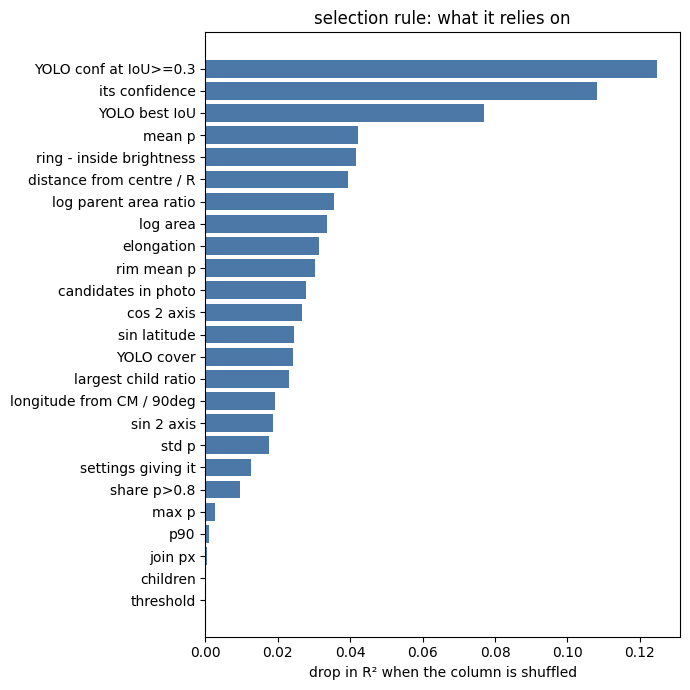

In [8]:
# what the rule uses: permutation importance on its own training candidates
from sklearn.inspection import permutation_importance
NAMES = FEATURES + ["YOLO best IoU", "its confidence", "YOLO conf at IoU>=0.3", "YOLO cover"]
Xa = np.concatenate([f["X"][:, K.GEO_YOLO_COLS] for f in frames])
ya = np.concatenate([f["Y"].mean(axis=1) for f in frames])
imp = permutation_importance(rule, Xa, ya, n_repeats=3, random_state=0, n_jobs=1)
order = np.argsort(imp.importances_mean)
plt.figure(figsize=(7, 7))
plt.barh([NAMES[i] for i in order], imp.importances_mean[order], color="#4c78a8")
plt.xlabel("drop in R² when the column is shuffled"); plt.title("selection rule: what it relies on")
plt.tight_layout(); plt.show()

In [9]:
# the cut: the rule (trained on folds 1-4) on fold 0's ensemble map, which averages five U-Nets
# trained without fold 0 and the Qwen map, exactly as the test map averages its models
t0f = truth[0]
stems0 = [s for _, s, _ in t0f["frames"]]
mixed0 = K.mix_dump(D, f"{VARIANT}mix0", K.ENS0.split("+"), EXTRAS, K.QSEG_W, "val", stems0)
cache0 = D / f"pool_{VARIANT}mix0_{K.VIEW}"
cache0.mkdir(parents=True, exist_ok=True)
e0 = K.one_setting(list(pool.imap(K.pool_job, [(str(D), mixed0, stem, t0f["cache"], f, sets, str(cache0), True)
                                                for f, stem, sets in t0f["frames"]])))
e0 = K.add_neighbours(e0, D, [mixed0] * len(e0), "val", np.zeros(len(e0), int), pool.imap)
e0 = K.add_yolo(e0, [yolo[0]] * len(e0), "val")
tr, _ = K.transfer(frames, folds, e0, K.GEO_YOLO_COLS)
CUT = tr["on_ens0_best_cut"]["cut"]
print("fold 0, nested cut:", tr["on_ens0_nested_cut"])
print("cut for the test map:", CUT)

fold 0, nested cut: {'PQ': np.float64(0.4578), 'SQ': np.float64(0.6791), 'RQ': np.float64(0.6741), 'TP': np.float64(1172.0), 'FP': np.float64(456.0), 'FN': np.float64(677.0)}
cut for the test map: 0.18


## 6. The test file

The test map gives candidates the same way. The rule scores each candidate once per YOLO fold model, and the five scores are averaged. Candidates above the cut are encoded as COCO RLE. The file is then checked by `src/verify_submission.py`, which decodes every mask as the scorer does, and compared with the submitted file.

In [10]:
csv = OUT / f"submission_kf10{VARIANT}_rule_geo_yolo.csv"
info = K.write_csv(D, final_map, test_files, csv, rule, CUT, K.GEO_YOLO_COLS, yolo=yolo)
print(K.verify(csv)["tail"])
md5 = hashlib.md5(csv.read_bytes()).hexdigest()
print(f"{csv.name}: {info['rows']} filaments, MD5 {md5}",
      "-- identical to the submitted file" if md5 == SUBMITTED_MD5 else "-- differs from the submitted file")
pool.close()

wrote submission_kf10q_rule_geo_yolo.csv: 1195 rows, 6.64 per image, 3 empty
verify submission_kf10q_rule_geo_yolo.csv: exit 0
rows: 1195
test images on disk: 180
decoded masks: 1195
mask area px: min 150 median 1315 max 21418   (train ground truth: median 1228)
filaments per image: mean 6.75 median 6 max 16   (train: mean 7.1, median 7)

WARN  3 test images have no prediction at all, e.g. ['20170708164010Mh', '20200310113230Ch', '20211214174010Mh']

OK to submit (1 warning(s))

mask area px: min 150 median 1315 max 21418   (train ground truth: median 1228)
filaments per image: mean 6.75 median 6 max 16   (train: mean 7.1, median 7)

WARN  3 test images have no prediction at all, e.g. ['20170708164010Mh', '20200310113230Ch', '20211214174010Mh']

OK to submit (1 warning(s))

submission_kf10q_rule_geo_yolo.csv: 1195 filaments, MD5 003770e26a0f962a45c8227320e1e145 -- identical to the submitted file


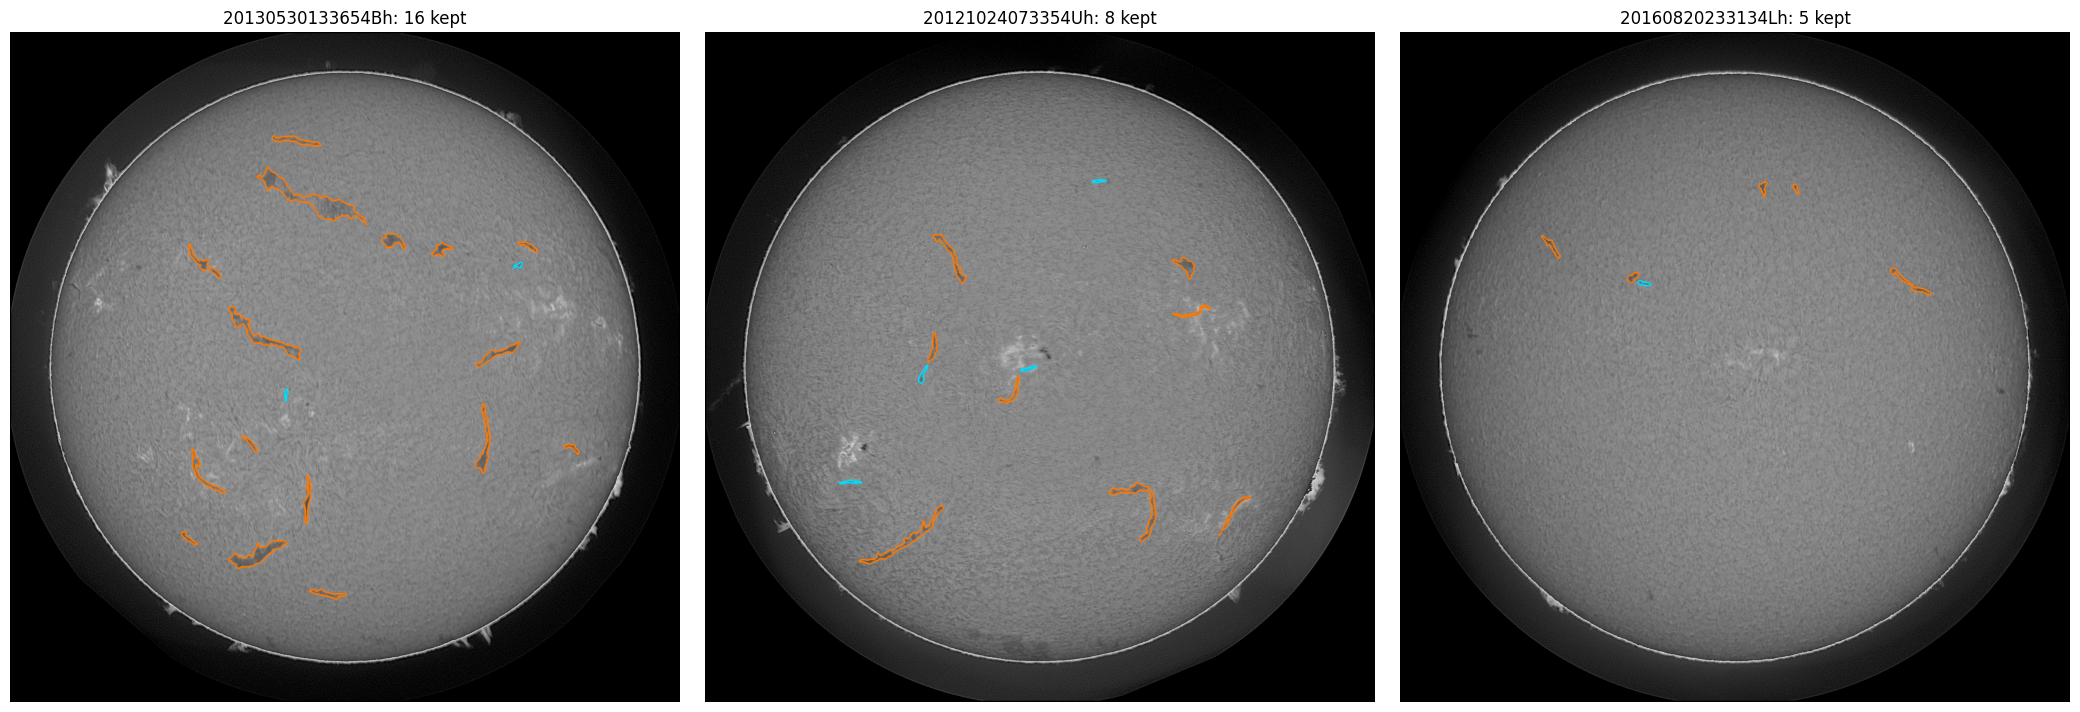

In [11]:
# kept (orange) and discarded (cyan) candidates on three test photographs
rows = pd.read_csv(csv)
fig, ax = plt.subplots(1, 3, figsize=(21, 7))
for a, stem in zip(ax, [STEM, test_stems[40], test_stems[120]]):
    im = cv2.imread(str(te_dir / f"{stem}.jpeg"), cv2.IMREAD_GRAYSCALE)
    over = cv2.cvtColor(im, cv2.COLOR_GRAY2RGB)
    cands, _ = C.candidates(P.load_map(D, final_map, "test", stem), im, run.b0_deg(stem))
    for c in cands:
        if C.ONE_SETTING in c["from"]:
            m = np.zeros(im.shape, np.uint8)
            m[c["y0"]:c["y0"] + c["m"].shape[0], c["x0"]:c["x0"] + c["m"].shape[1]] = c["m"]
            cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            cv2.drawContours(over, cs, -1, (0, 220, 255), 3)
    kept = rows[rows.filament_id.str.rsplit("_", n=1).str[0] == stem]
    for counts in kept.segmentation_rle:
        m = np.ascontiguousarray(run.mu.decode({"size": [run.FULL, run.FULL], "counts": counts.encode()}))
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(over, cs, -1, (255, 120, 0), 4)
    a.imshow(over); a.set_title(f"{stem}: {len(kept)} kept"); a.axis("off")
plt.tight_layout(); plt.show()

## 7. Effect of each component

95% bootstrap intervals over photographs. OOF means out-of-fold on all 707 photographs; "ens." means fold 0's ensemble.

| change | ΔPQ |
|---|---|
| D4 symmetry averaging (OOF) | +0.005 [+0.002, +0.009] |
| ResNet-50 + ResNet-34 vs ResNet-50 (OOF) | +0.004 [+0.001, +0.007] |
| selection rule (OOF) | +0.012 [+0.008, +0.017] |
| heliographic features in the rule (ens.) | +0.005 [+0.000, +0.010] |
| Qwen map + YOLO11 features (ens.) | +0.006 [+0.001, +0.012] |
| neighbouring frames carried by differential rotation (OOF) | −0.002 [−0.004, −0.000] |
| pixel random forest added to the ensemble (ens.) | −0.001 [−0.007, +0.005] |

For comparison:
- One expert scored against the others reaches PQ 0.351 on fold 0.
- At the pixel level the submitted map agrees with the experts (F1 0.71) better than one expert agrees with the rest (0.65).

The report lists the approaches that did not reach the submission: the physical per-pixel table with differential rotation, the per-pixel network, Mask R-CNN, self-training, and a vision-language judge.